In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings



In [5]:
file_path ="/content/purchase_transactions.csv"
transactions = pd.read_csv(file_path)
print("Shape:", transactions.shape)

Shape: (779425, 16)


In [6]:
print("Dataset Shape:", transactions.shape)

print("\nColumns:")
print(transactions.columns.tolist())

print("\nData Types:")
print(transactions.dtypes)

print("\nMissing Values:")
print(transactions.isnull().sum())

Dataset Shape: (779425, 16)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancellation', 'IsNegativeQuantity', 'Revenue', 'InvoiceYear', 'InvoiceMonth', 'InvoiceDay', 'InvoiceHour', 'InvoiceDayOfWeek']

Data Types:
Invoice                 int64
StockCode              object
Description            object
Quantity                int64
InvoiceDate            object
UnitPrice             float64
CustomerID            float64
Country                object
IsCancellation           bool
IsNegativeQuantity       bool
Revenue               float64
InvoiceYear             int64
InvoiceMonth            int64
InvoiceDay              int64
InvoiceHour             int64
InvoiceDayOfWeek        int64
dtype: object

Missing Values:
Invoice               0
StockCode             0
Description           0
Quantity              0
InvoiceDate           0
UnitPrice             0
CustomerID            0
Country               0
IsCancella

In [7]:
transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"],
    errors="coerce"
)

transactions["CustomerID"] = transactions["CustomerID"].astype("string")

transactions["Invoice"] = transactions["Invoice"].astype("string")

transactions["Quantity"] = pd.to_numeric(
    transactions["Quantity"],
    errors="coerce"
)

transactions["UnitPrice"] = pd.to_numeric(
    transactions["UnitPrice"],
    errors="coerce"
)

transactions["Revenue"] = pd.to_numeric(
    transactions["Revenue"],
    errors="coerce"
)

In [8]:
transactions = transactions.dropna(
    subset=[
        "CustomerID",
        "InvoiceDate",
        "Invoice",
        "Quantity",
        "UnitPrice",
        "Revenue"
    ]
).copy()

transactions = transactions.sort_values("InvoiceDate").reset_index(drop=True)

print("Shape after validation:", transactions.shape)

Shape after validation: (779425, 16)


In [9]:
data_start = transactions["InvoiceDate"].min()
data_end = transactions["InvoiceDate"].max()

print("First Transaction:", data_start)
print("Last Transaction:", data_end)

print(
    "Total Dataset Duration:",
    (data_end - data_start).days,
    "days"
)

First Transaction: 2009-12-01 07:45:00
Last Transaction: 2011-12-09 12:50:00
Total Dataset Duration: 738 days


In [10]:
OBSERVATION_DAYS = 180
PREDICTION_DAYS = 90

print("Observation Window:", OBSERVATION_DAYS, "days")
print("Prediction Window:", PREDICTION_DAYS, "days")

Observation Window: 180 days
Prediction Window: 90 days


In [11]:
data_start_date = data_start.normalize()
data_end_exclusive = data_end.normalize() + pd.Timedelta(days=1)

first_snapshot = data_start_date + pd.Timedelta(days=OBSERVATION_DAYS)

last_snapshot = data_end_exclusive - pd.Timedelta(days=PREDICTION_DAYS)

snapshot_dates = pd.date_range(
    start=first_snapshot,
    end=last_snapshot,
    freq="MS"
)

print("Number of Snapshots:", len(snapshot_dates))

print("\nSnapshot Dates:")
for date in snapshot_dates:
    print(date.date())

Number of Snapshots: 16

Snapshot Dates:
2010-06-01
2010-07-01
2010-08-01
2010-09-01
2010-10-01
2010-11-01
2010-12-01
2011-01-01
2011-02-01
2011-03-01
2011-04-01
2011-05-01
2011-06-01
2011-07-01
2011-08-01
2011-09-01


In [27]:

def create_customer_features(observation_data, snapshot_date):

    # ------------------------------------------------
    # 1. CREATE ORDER-LEVEL DATA
    # ------------------------------------------------

    # Each invoice represents one order.
    # Multiple product rows can belong to the same invoice.

    order_level = observation_data.groupby(
        ["CustomerID", "Invoice"]
    ).agg(
        OrderDate=("InvoiceDate", "min"),
        OrderRevenue=("Revenue", "sum"),
        OrderQuantity=("Quantity", "sum")
    ).reset_index()

    # ------------------------------------------------
    # 2. IDENTIFY WEEKEND ORDERS
    # ------------------------------------------------

    order_level["IsWeekend"] = (
        order_level["OrderDate"].dt.dayofweek >= 5
    ).astype(int)

    # ------------------------------------------------
    # 3. CALCULATE BASIC CUSTOMER FEATURES
    # ------------------------------------------------

    customer_features = observation_data.groupby(
        "CustomerID"
    ).agg(
        Monetary=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        ActiveDays=(
            "InvoiceDate",
            lambda x: x.dt.normalize().nunique()
        ),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    ).reset_index()

    # ------------------------------------------------
    # 4. CALCULATE ORDER-LEVEL CUSTOMER FEATURES
    # ------------------------------------------------

    order_features = order_level.groupby(
        "CustomerID"
    ).agg(
        Frequency=("Invoice", "nunique"),
        AverageOrderValue=("OrderRevenue", "mean"),
        WeekendOrderCount=("IsWeekend", "sum")
    ).reset_index()

    # Merge order-level features
    customer_features = customer_features.merge(
        order_features,
        on="CustomerID",
        how="left"
    )

    # ------------------------------------------------
    # 5. CALCULATE AVERAGE DAYS BETWEEN ORDERS
    # ------------------------------------------------

    order_level = order_level.sort_values(
        ["CustomerID", "OrderDate"]
    )

    order_level["DaysBetweenOrders"] = (
        order_level.groupby("CustomerID")["OrderDate"]
        .diff()
        .dt.total_seconds() / 86400
    )

    gap_features = order_level.groupby(
        "CustomerID"
    )["DaysBetweenOrders"].mean().reset_index()

    gap_features.rename(
        columns={
            "DaysBetweenOrders": "AvgDaysBetweenOrders"
        },
        inplace=True
    )

    customer_features = customer_features.merge(
        gap_features,
        on="CustomerID",
        how="left"
    )

    # ------------------------------------------------
    # 6. CALCULATE RECENCY
    # ------------------------------------------------

    customer_features["RecencyDays"] = (
        snapshot_date -
        customer_features["LastPurchase"]
    ).dt.days

    # ------------------------------------------------
    # 7. CORRECT CUSTOMER TENURE
    # ------------------------------------------------

    # Find the customer's earliest purchase in the
    # entire available dataset before the snapshot.

    first_purchase_history = (
        transactions[
            transactions["InvoiceDate"] < snapshot_date
        ]
        .groupby("CustomerID")["InvoiceDate"]
        .min()
    )

    customer_features["FirstObservedPurchase"] = (
        customer_features["CustomerID"]
        .map(first_purchase_history)
    )

    customer_features["CustomerTenureDays"] = (
        snapshot_date -
        customer_features["FirstObservedPurchase"]
    ).dt.days

    # ------------------------------------------------
    # 8. ADD MULTIPLE-ORDER INDICATOR
    # ------------------------------------------------

    customer_features["HasMultipleOrders"] = (
        customer_features["Frequency"] > 1
    ).astype(int)

    # ------------------------------------------------
    # 9. ADD SNAPSHOT DATE
    # ------------------------------------------------

    customer_features["SnapshotDate"] = snapshot_date

    # ------------------------------------------------
    # 10. RETURN CUSTOMER FEATURES
    # ------------------------------------------------

    return customer_features


In [14]:
all_snapshots = []

for snapshot in snapshot_dates:

    print("Processing snapshot:", snapshot.date())

    # Historical observation window
    observation_start = snapshot - pd.Timedelta(
        days=OBSERVATION_DAYS
    )

    observation_data = transactions[
        (transactions["InvoiceDate"] >= observation_start) &
        (transactions["InvoiceDate"] < snapshot)
    ].copy()

    # Future prediction window
    prediction_end = snapshot + pd.Timedelta(
        days=PREDICTION_DAYS
    )

    future_data = transactions[
        (transactions["InvoiceDate"] >= snapshot) &
        (transactions["InvoiceDate"] < prediction_end)
    ].copy()

    # Calculate historical customer features
    snapshot_features = create_customer_features(
        observation_data,
        snapshot
    )

    # Count future orders for each customer
    future_orders = future_data.groupby(
        "CustomerID"
    )["Invoice"].nunique().reset_index()

    future_orders.rename(
        columns={"Invoice": "FutureOrders90D"},
        inplace=True
    )

    # Attach future order information
    snapshot_features = snapshot_features.merge(
        future_orders,
        on="CustomerID",
        how="left"
    )

    snapshot_features["FutureOrders90D"] = (
        snapshot_features["FutureOrders90D"]
        .fillna(0)
        .astype(int)
    )

    # Generate churn label
    snapshot_features["Churn90D"] = (
        snapshot_features["FutureOrders90D"] == 0
    ).astype(int)

    all_snapshots.append(snapshot_features)

# Combine all snapshot periods
temporal_dataset = pd.concat(
    all_snapshots,
    ignore_index=True
)

print("\nTemporal Dataset Created!")
print("Shape:", temporal_dataset.shape)

temporal_dataset.head()

Processing snapshot: 2010-06-01
Processing snapshot: 2010-07-01
Processing snapshot: 2010-08-01
Processing snapshot: 2010-09-01
Processing snapshot: 2010-10-01
Processing snapshot: 2010-11-01
Processing snapshot: 2010-12-01
Processing snapshot: 2011-01-01
Processing snapshot: 2011-02-01
Processing snapshot: 2011-03-01
Processing snapshot: 2011-04-01
Processing snapshot: 2011-05-01
Processing snapshot: 2011-06-01
Processing snapshot: 2011-07-01
Processing snapshot: 2011-08-01
Processing snapshot: 2011-09-01

Temporal Dataset Created!
Shape: (48079, 17)


,CustomerID,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,Frequency,AverageOrderValue,WeekendOrderCount,AvgDaysBetweenOrders,RecencyDays,CustomerTenureDays,SnapshotDate,HasMultipleOrders,FutureOrders90D,Churn90D
0,12346.0,230.55,51,7,6,2009-12-14 08:34:00,2010-03-02 13:08:00,10,23.0550,0,8.687809,90,168,2010-06-01,1,1,0
1,12349.0,1268.52,474,47,2,2010-04-29 13:20:00,2010-05-18 09:57:00,2,634.2600,0,18.859028,13,32,2010-06-01,1,0,1
2,12355.0,488.21,303,22,1,2010-05-21 11:59:00,2010-05-21 11:59:00,1,488.2100,0,NaN,10,10,2010-06-01,0,0,1
3,12358.0,1429.83,309,17,1,2009-12-08 07:59:00,2009-12-08 07:59:00,1,1429.8300,0,NaN,174,174,2010-06-01,0,1,0
4,12359.0,1522.23,777,65,4,2009-12-05 13:32:00,2010-03-23 08:55:00,4,380.5575,1,35.935880,69,177,2010-06-01,1,1,0


In [15]:
print("Dataset Shape:", temporal_dataset.shape)

print("\nColumns:")
print(temporal_dataset.columns.tolist())

print("\nMissing Values:")
print(temporal_dataset.isnull().sum())

print("\nSample Records:")
display(temporal_dataset.head())

Dataset Shape: (48079, 17)

Columns:
['CustomerID', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'ActiveDays', 'FirstPurchase', 'LastPurchase', 'Frequency', 'AverageOrderValue', 'WeekendOrderCount', 'AvgDaysBetweenOrders', 'RecencyDays', 'CustomerTenureDays', 'SnapshotDate', 'HasMultipleOrders', 'FutureOrders90D', 'Churn90D']

Missing Values:
CustomerID                  0
Monetary                    0
TotalQuantity               0
UniqueProducts              0
ActiveDays                  0
FirstPurchase               0
LastPurchase                0
Frequency                   0
AverageOrderValue           0
WeekendOrderCount           0
AvgDaysBetweenOrders    21794
RecencyDays                 0
CustomerTenureDays          0
SnapshotDate                0
HasMultipleOrders           0
FutureOrders90D             0
Churn90D                    0
dtype: int64

Sample Records:


,CustomerID,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,Frequency,AverageOrderValue,WeekendOrderCount,AvgDaysBetweenOrders,RecencyDays,CustomerTenureDays,SnapshotDate,HasMultipleOrders,FutureOrders90D,Churn90D
0,12346.0,230.55,51,7,6,2009-12-14 08:34:00,2010-03-02 13:08:00,10,23.0550,0,8.687809,90,168,2010-06-01,1,1,0
1,12349.0,1268.52,474,47,2,2010-04-29 13:20:00,2010-05-18 09:57:00,2,634.2600,0,18.859028,13,32,2010-06-01,1,0,1
2,12355.0,488.21,303,22,1,2010-05-21 11:59:00,2010-05-21 11:59:00,1,488.2100,0,NaN,10,10,2010-06-01,0,0,1
3,12358.0,1429.83,309,17,1,2009-12-08 07:59:00,2009-12-08 07:59:00,1,1429.8300,0,NaN,174,174,2010-06-01,0,1,0
4,12359.0,1522.23,777,65,4,2009-12-05 13:32:00,2010-03-23 08:55:00,4,380.5575,1,35.935880,69,177,2010-06-01,1,1,0


Churn90D
1    24490
0    23589
Name: count, dtype: int64

Churn Percentage:
Churn90D
1    50.937
0    49.063
Name: proportion, dtype: float64


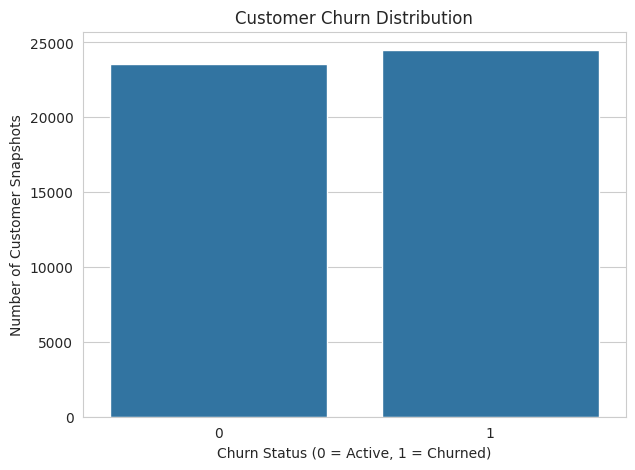

In [16]:
churn_distribution = temporal_dataset["Churn90D"].value_counts()

print(churn_distribution)

print("\nChurn Percentage:")
print(
    temporal_dataset["Churn90D"]
    .value_counts(normalize=True) * 100
)
#visual representation
plt.figure(figsize=(7, 5))

sns.countplot(
    data=temporal_dataset,
    x="Churn90D"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status (0 = Active, 1 = Churned)")
plt.ylabel("Number of Customer Snapshots")

plt.show()

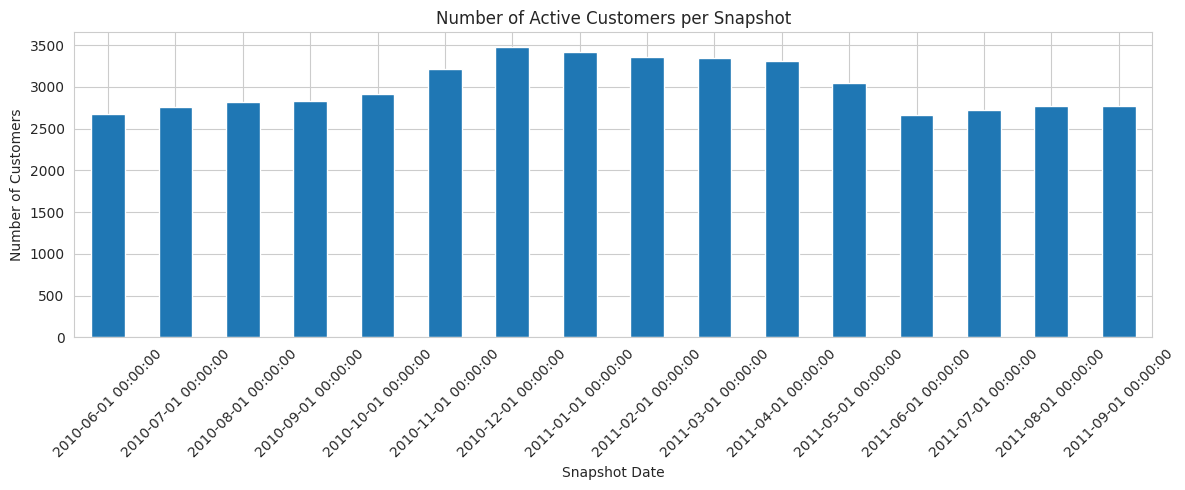

In [17]:
snapshot_counts = temporal_dataset.groupby(
    "SnapshotDate"
)["CustomerID"].nunique()

plt.figure(figsize=(12, 5))

snapshot_counts.plot(kind="bar")

plt.title("Number of Active Customers per Snapshot")
plt.xlabel("Snapshot Date")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
DATA_PATH = "/content"
OUTPUT_PATH = os.path.join(DATA_PATH, "temporal_customer_dataset.csv")

temporal_dataset.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Temporal dataset saved successfully!")
print("Location:", OUTPUT_PATH)

Temporal dataset saved successfully!
Location: /content/temporal_customer_dataset.csv


In [26]:
# Create a flag for missing order intervals

temporal_dataset["NoOrderIntervalAvailable"] = (
    temporal_dataset["AvgDaysBetweenOrders"].isna()
).astype(int)

print(
    temporal_dataset["NoOrderIntervalAvailable"]
    .value_counts()
)

print(
    temporal_dataset["NoOrderIntervalAvailable"]
    .value_counts(normalize=True) * 100
)

NoOrderIntervalAvailable
0    26285
1    21794
Name: count, dtype: int64
NoOrderIntervalAvailable
0    54.670438
1    45.329562
Name: proportion, dtype: float64
